# **SVR (Support Vector Regression) on the Concrete Dataset**
Target: `strength` (concrete compressive strength, MPa)

**SVR:** fits a line/curve that keeps most points inside a margin (a tube) of width `epsilon`. Errors inside the tube are ignored, only points outside the tube are penalized.

Hyperparameters tuned with `GridSearchCV` (5-fold, stratified):
- `kernel` : `rbf` (curved, non-linear) or `linear` (straight)
- `C` : penalty for errors (big C = fit training data tightly, can overfit)
- `epsilon` : width of the tube (errors smaller than this are ignored)
- `gamma` : how far one sample's influence reaches (only for `rbf`)

> SVR works on distances, so features **must be scaled**. `StandardScaler` is inside the Pipeline.

### Import

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Dataset and Stratified Split
High-strength samples are rare, so we split on strength ranges to keep the same ratio in train and test.

In [7]:
df = pd.read_csv('../1. Data_Preprocessing/For_Regression/concrete_after_preprocessing.csv')
x = df.drop('strength', axis=1)
y = df['strength']

#Strength ranges (used only for stratification)
bins = pd.cut(y, bins=[0, 20, 35, 50, 65, 100], labels=False)

x_train, x_test, y_train, y_test, bins_train, _ = train_test_split(
    x, y, bins, test_size=0.2, random_state=42, stratify=bins)
print(x_train.shape, x_test.shape)

#Stratified 5-fold CV
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(x_train, bins_train))

(804, 8) (201, 8)


### SVR Pipeline and Hyperparameter Grid
Target `strength` is in MPa (values 2 to 82), so `C` needs bigger values than the usual 1.

In [8]:
svr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVR())
])

#Two grids: rbf kernel (with gamma) and linear kernel (no gamma)
param_grid = [
    {'model__kernel': ['rbf'],
     'model__C': [1, 10, 100, 1000],
     'model__gamma': ['scale', 0.01, 0.05, 0.1, 0.5],
     'model__epsilon': [0.1, 1, 3]},

    {'model__kernel': ['linear'],
     'model__C': [0.1, 1, 10, 100],
     'model__epsilon': [0.1, 1, 3]},
]

### GridSearchCV

In [9]:
%%time
grid = GridSearchCV(svr_pipe, param_grid, cv=cv, scoring='r2', n_jobs=-1, return_train_score=True)
grid.fit(x_train, y_train)

print('Best Params      :', grid.best_params_)
print('Best CV R2 score :', round(grid.best_score_, 4))
print('Train R2 score   :', round(grid.cv_results_['mean_train_score'][grid.best_index_], 4))

Best Params      : {'model__C': 100, 'model__epsilon': 3, 'model__gamma': 0.1, 'model__kernel': 'rbf'}
Best CV R2 score : 0.9138
Train R2 score   : 0.9534
CPU times: total: 5.17 s
Wall time: 52.4 s


### Test Set Evaluation

In [10]:
best_svr = grid.best_estimator_
y_pred = best_svr.predict(x_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print('MAE  :', round(mae, 4))
print('MSE  :', round(mse, 4))
print('RMSE :', round(rmse, 4))
print('R2   :', round(r2, 4))

#Best result of each kernel
res = pd.DataFrame(grid.cv_results_)
res.groupby('param_model__kernel')['mean_test_score'].max().round(4)

MAE  : 3.6819
MSE  : 27.255
RMSE : 5.2206
R2   : 0.8982


param_model__kernel
linear    0.8099
rbf       0.9138
Name: mean_test_score, dtype: float64

### Visualization

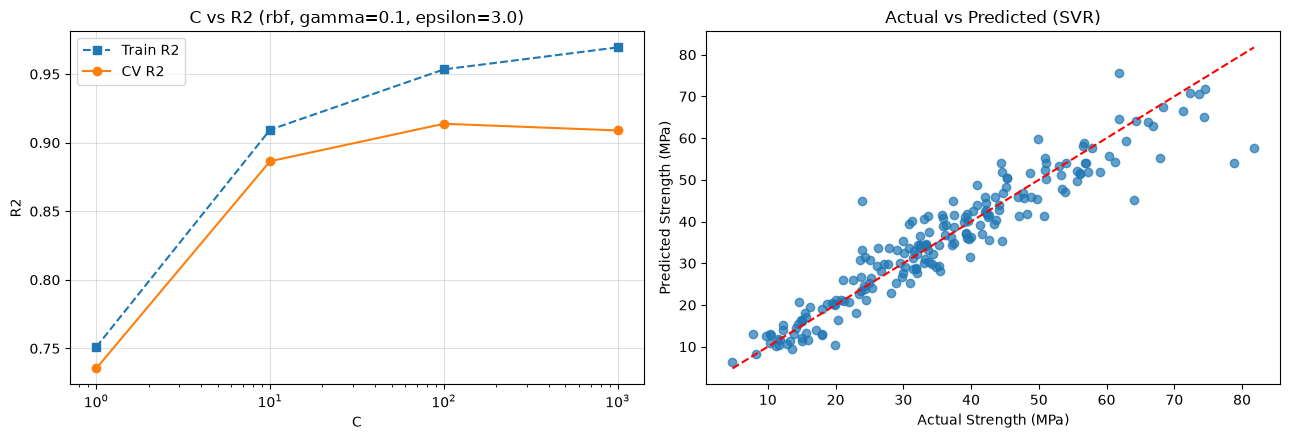

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

#C vs R2 (best gamma / epsilon of rbf kernel)
rbf = res[res['param_model__kernel'] == 'rbf'].copy()
best_rbf = rbf.sort_values('mean_test_score', ascending=False).iloc[0]
r = rbf[(rbf['param_model__gamma'] == best_rbf['param_model__gamma']) &
        (rbf['param_model__epsilon'] == best_rbf['param_model__epsilon'])].sort_values('param_model__C')

ax[0].semilogx(r['param_model__C'].astype(float), r['mean_train_score'], 's--', label='Train R2')
ax[0].semilogx(r['param_model__C'].astype(float), r['mean_test_score'], 'o-', label='CV R2')
ax[0].set_xlabel('C'); ax[0].set_ylabel('R2')
ax[0].set_title(f"C vs R2 (rbf, gamma={best_rbf['param_model__gamma']}, epsilon={best_rbf['param_model__epsilon']})")
ax[0].legend(); ax[0].grid(alpha=0.4)

#Actual vs Predicted
ax[1].scatter(y_test, y_pred, alpha=0.7)
ax[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
ax[1].set_xlabel('Actual Strength (MPa)'); ax[1].set_ylabel('Predicted Strength (MPa)')
ax[1].set_title('Actual vs Predicted (SVR)')

plt.tight_layout(); plt.show()

### Save the Model (.pkl)
Best SVR is trained once more on all data, then saved with `joblib`.

In [12]:
from sklearn.base import clone

final_svr = clone(best_svr)
final_svr.fit(x, y)

joblib.dump(final_svr, 'svr_concrete_model.pkl')
print('Saved: svr_concrete_model.pkl')

Saved: svr_concrete_model.pkl


### Load and Predict
These 5 rows were also used to train the final model, so predictions look better than reality. This cell only checks that the saved file loads and works. The honest accuracy is the **Test Set Evaluation** above (trained without the test rows).

In [13]:
model = joblib.load('svr_concrete_model.pkl')

new_rows = x_test.iloc[:5]
print('Predicted strength:', model.predict(new_rows).round(2))
print('Actual strength   :', y_test.iloc[:5].round(2).values)

Predicted strength: [21.44 13.3  15.03 29.26 66.64]
Actual strength   : [21.97 15.07 18.03 30.23 68.3 ]


### Download (Google Colab only)

In [9]:
try:
    from google.colab import files
    files.download('svr_concrete_model.pkl')
except ImportError:
    print('Not Colab - file is saved in the notebook folder.')

Not Colab - file is saved in the notebook folder.
